200 simulated days, 11 bins
corr(distance to dock, base fill rate) = +0.29  (n=11, weak evidence either way)
 bin  base_rate  dock_min  share_days_hit_80  median_cross_min  tier
   3       45.7         4                1.0             150.0     1
  10       39.4         6                1.0             158.0     1
   4       37.6         5                1.0             170.0     1
   1       34.4         3                1.0             200.0     0
   5       34.4         5                1.0             187.0     1
   6       33.9         3                1.0             193.0     0
   2       33.1         5                1.0             192.0     1
   7       26.9         3                1.0             213.0     2
   9       25.4         6                1.0             228.0     1
   0       21.0         5                1.0             255.0     2
   8       20.3         1                1.0             254.0     2


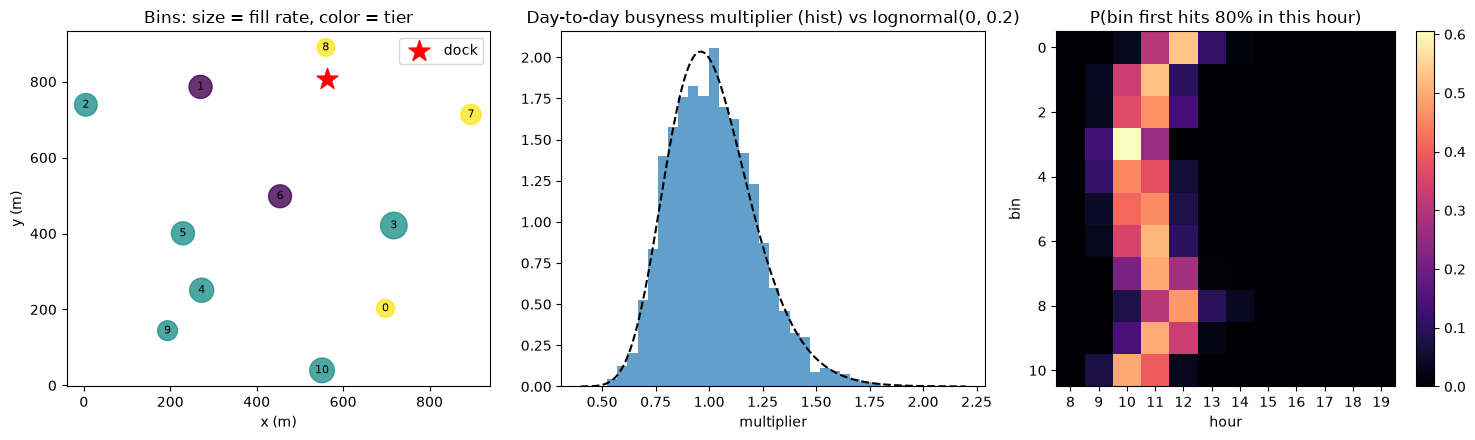


Minutes from crossing a threshold to overflow if nobody comes:
     share_overflow_if_ignored  median   p10    p90  share_under_15
thr                                                                
60                         1.0    91.0  68.0  128.0            0.00
70                         1.0    66.0  46.0   94.0            0.00
80                         1.0    41.0  29.0   62.0            0.00
90                         1.0    19.0  13.0   30.0            0.25


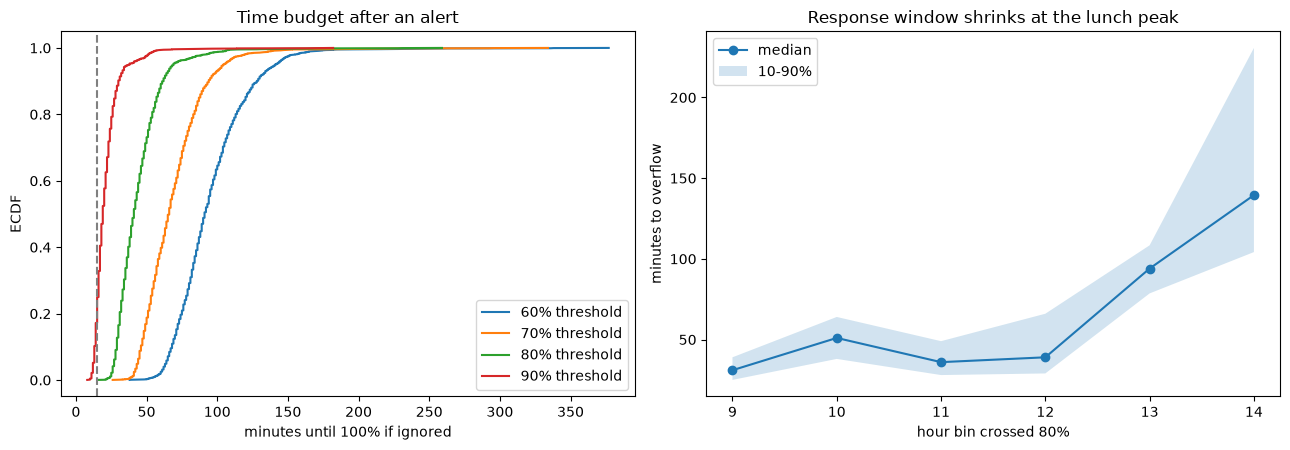


Forecast of fill 30 min ahead, tested on 67 unseen days:
                              model  MAE_pct  RMSE_pct     R2  alert_precision  alert_recall
                 naive: global mean    3.244     4.036 -0.001            0.896         0.819
    persistence: repeat last 30 min    3.292     3.856  0.087            0.899         0.829
base rate x schedule (no live data)    1.838     2.419  0.640            0.916         0.929
           ridge (slope + schedule)    0.837     1.103  0.925            0.962         0.965


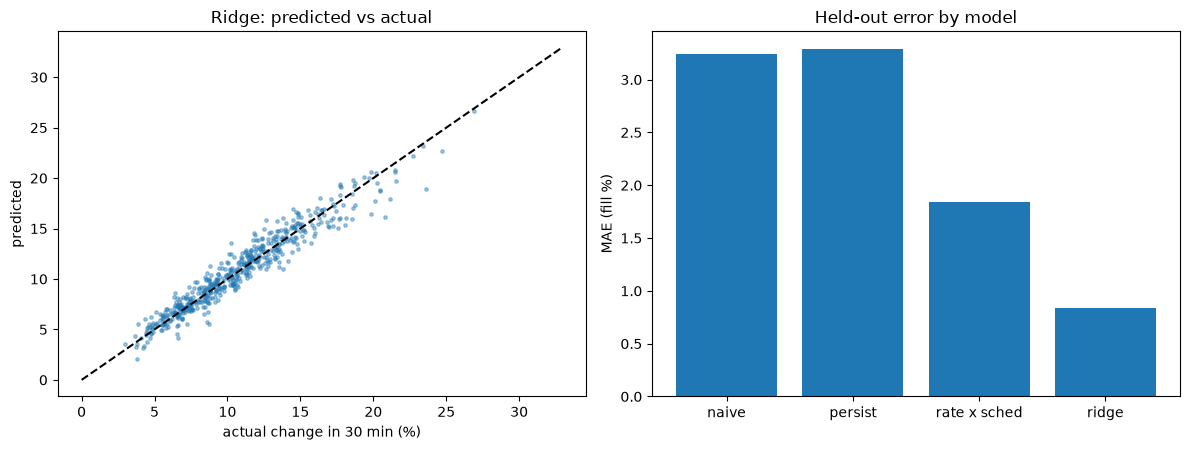


max asymmetry = 0 min; triangle-inequality violations = 0 of 1320 triples (ceil rounding can cause a few)
 bin  rate  round_trip_min  workload
  10  39.4              12     473.0
   4  37.6              10     376.0
   3  45.7               8     365.0
   5  34.4              10     344.0
   2  33.1              10     331.0
Gini of per-bin workload = 0.24 (0 = even, 1 = one bin does everything)
  2 zones (k-means on location): workload shares = [0.52 0.48], max/min = 1.1x
  3 zones (k-means on location): workload shares = [0.31 0.35 0.34], max/min = 1.1x
  4 zones (k-means on location): workload shares = [0.34 0.19 0.23 0.24], max/min = 1.8x


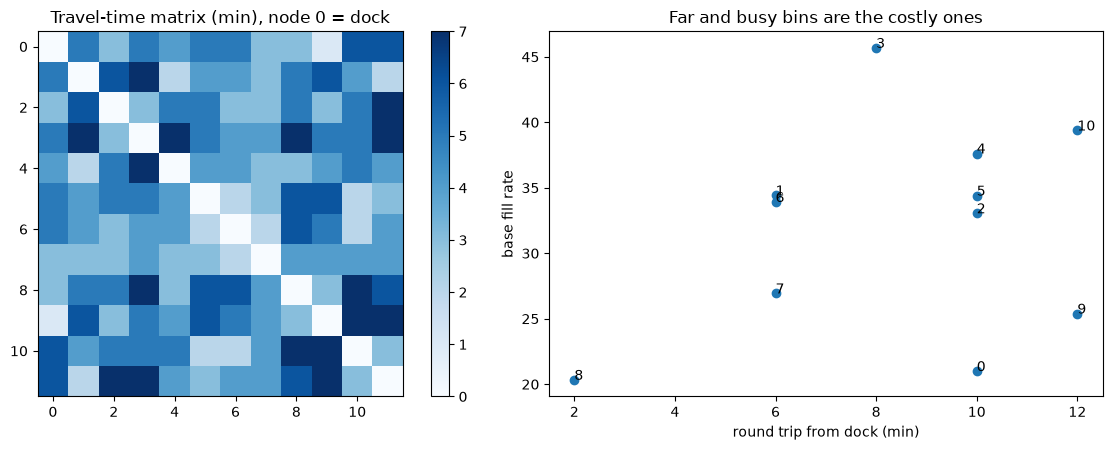


[E skipped] results/runs_main.csv not found. Run the fleet-sizing notebook first.

Done. Figures in results/figs/, tables in results/.


In [1]:
# %% [markdown]
# # Data science extras for the waste-fleet project
# Runs standalone (VS Code / Jupyter "# %%" cells, or `python ds_extras.py`).
# It rebuilds the SAME stand-in world as the fleet-sizing notebook (same map, rates,
# demand curve, per-seed noise), so results line up. Swap in real data when available.
#
# Sections (and the repo file each one supports):
#   A. Demand EDA + service tiers ............ sites.py / seed_ucsd / seed_airport
#   B. Response window + alert threshold ..... notify.py / supervisor.py
#   C. Fill forecasting vs baselines ......... optimize.py (predictive dispatch)
#   D. Travel-time matrix + workload ......... navigation.py / dispatcher.py
#   E. Simulation validation (needs runs csv). sim.py
# Outputs: results/figs/*.png and results/*.csv

# %%
import math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results/figs", exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 5)
QUICK = False
N_SEEDS = 40 if QUICK else 200

# ---- same world as the notebook (do not change, or results will not match) ----
_layout = np.random.default_rng(7)
N_NODES = 12
XY = _layout.uniform(0, 900, size=(N_NODES, 2))
SPEED = 130.0
T = np.ceil(np.linalg.norm(XY[:, None] - XY[None], axis=2) / SPEED).astype(int)
N_BINS = N_NODES - 1
BASE_RATE = _layout.uniform(20, 48, size=N_BINS)
DAY_MIN, START_HOUR = 720, 8


def demand_curve(h):
    return (0.25 + 1.2 * math.exp(-((h - 12.5) / 1.2) ** 2)
            + 0.6 * math.exp(-((h - 10.0) / 0.6) ** 2)
            + 0.6 * math.exp(-((h - 15.0) / 0.7) ** 2))


CURVE = np.array([demand_curve(START_HOUR + t / 60) for t in range(DAY_MIN)])


def fill_paths(seed, scale=1.0):
    """Fill level (%) of every bin every minute with NO robots: shape (DAY_MIN, N_BINS).
    Uses the same RNG draw order as simulate() so seed k is the same day."""
    rng = np.random.default_rng(seed)
    day_mult = rng.lognormal(0, 0.2, N_BINS)
    noise = np.clip(1 + 0.3 * rng.standard_normal((DAY_MIN, N_BINS)), 0, None)
    start = rng.uniform(0, 50, N_BINS)
    inc = BASE_RATE * day_mult * CURVE[:, None] * scale * noise / 60
    return np.minimum(start + np.cumsum(inc, axis=0), 100.0), day_mult


PATHS = [fill_paths(s)[0] for s in range(N_SEEDS)]
DAYMULT = np.array([fill_paths(s)[1] for s in range(N_SEEDS)])
print(f"{N_SEEDS} simulated days, {N_BINS} bins")


# %% [markdown]
# ## C. Fill forecasting vs baselines  (optimize.py: predictive dispatch)
# Task: predict a bin's fill 30 minutes ahead, then flag "will cross 80% soon".
# Train and test use DIFFERENT simulated days. Baselines first, then a model.
# Caveat to say out loud: the data is simulated, so this shows the method and the
# value of each feature; rerun on real sensor logs before claiming real accuracy.

# %%
H = 30
TRAIN = range(0, N_SEEDS * 2 // 3)
TEST = range(N_SEEDS * 2 // 3, N_SEEDS)


def make_rows(seeds):
    X, y, meta = [], [], []
    for s in seeds:
        P = PATHS[s]
        for t in range(60, DAY_MIN - H, 10):
            cur, slope30, slope60 = P[t], P[t] - P[t - 30], P[t] - P[t - 60]
            ahead = CURVE[t:t + H].mean()                     # known schedule (class breaks, lunch)
            for i in range(N_BINS):
                if cur[i] >= 80:                              # already due; not a forecasting case
                    continue
                X.append([cur[i], slope30[i], slope60[i], ahead, BASE_RATE[i] * ahead,
                          CURVE[t - 30:t].mean() * BASE_RATE[i]])
                y.append(P[t + H][i] - cur[i])
                meta.append((s, t, i, cur[i]))
    return np.array(X), np.array(y), pd.DataFrame(meta, columns=["seed", "t", "bin", "cur"])


Xtr, ytr, mtr = make_rows(TRAIN)
Xte, yte, mte = make_rows(TEST)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9


def ridge_fit(X, y, lam=1.0):
    A = np.c_[np.ones(len(X)), (X - mu) / sd]
    return np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ y)


def ridge_pred(w, X):
    return np.c_[np.ones(len(X)), (X - mu) / sd] @ w


w = ridge_fit(Xtr, ytr)
pred = {
    "naive: global mean": np.full(len(yte), ytr.mean()),
    "persistence: repeat last 30 min": Xte[:, 1],
    "base rate x schedule (no live data)": Xte[:, 4] / 60 * H,
    "ridge (slope + schedule)": ridge_pred(w, Xte),
}
res = []
for name, p in pred.items():
    err = yte - p
    cls_true = (mte.cur.values + yte) >= 80
    cls_pred = (mte.cur.values + p) >= 80
    tp = (cls_true & cls_pred).sum()
    res.append({"model": name, "MAE_pct": np.abs(err).mean(), "RMSE_pct": math.sqrt((err ** 2).mean()),
                "R2": 1 - (err ** 2).sum() / ((yte - yte.mean()) ** 2).sum(),
                "alert_precision": tp / max(cls_pred.sum(), 1), "alert_recall": tp / max(cls_true.sum(), 1)})
res = pd.DataFrame(res)
res.to_csv("results/forecast_eval.csv", index=False)
print(f"\nForecast of fill {H} min ahead, tested on {len(set(mte.seed))} unseen days:")
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(yte[::20], pred["ridge (slope + schedule)"][::20], s=6, alpha=0.4)
lim = [0, max(yte.max(), 1)]
ax[0].plot(lim, lim, "k--"); ax[0].set(xlabel="actual change in 30 min (%)", ylabel="predicted", title="Ridge: predicted vs actual")
ax[1].bar(range(len(res)), res.MAE_pct, tick_label=["naive", "persist", "rate x sched", "ridge"])
ax[1].set(ylabel="MAE (fill %)", title="Held-out error by model"); plt.tight_layout()
plt.savefig("results/figs/C_forecast.png", dpi=130); plt.show()

# %% [markdown]
# ## D. Travel-time matrix and workload  (navigation.py / dispatcher.py)
# Is the matrix sane (symmetric, triangle inequality)? Which bins cost the most
# robot time? Workload = fill rate x round trip from dock, a quick fairness proxy.

# %%
sym_gap = np.abs(T - T.T).max()
viol = 0
for a in range(N_NODES):
    for b in range(N_NODES):
        for c in range(N_NODES):
            if len({a, b, c}) == 3 and T[a, c] > T[a, b] + T[b, c]:
                viol += 1
print(f"\nmax asymmetry = {sym_gap} min; triangle-inequality violations = {viol} of "
      f"{N_NODES * (N_NODES - 1) * (N_NODES - 2)} triples (ceil rounding can cause a few)")

round_trip = 2 * T[0, 1:]
work = rate * round_trip
work_df = pd.DataFrame({"bin": range(N_BINS), "rate": rate.round(1), "round_trip_min": round_trip,
                        "workload": work.round(0)}).sort_values("workload", ascending=False)
work_df.to_csv("results/bin_workload.csv", index=False)
print(work_df.head(5).to_string(index=False))


def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


print(f"Gini of per-bin workload = {gini(work):.2f} (0 = even, 1 = one bin does everything)")

# zoning check: k-means on bin coordinates -> how evenly would workload split across k robots?
def kmeans_xy(P, k, seed=0):
    rg = np.random.default_rng(seed)
    c = P[rg.choice(len(P), k, replace=False)]
    for _ in range(100):
        lab_ = np.argmin(((P[:, None] - c[None]) ** 2).sum(2), axis=1)
        c2 = np.array([P[lab_ == j].mean(0) if (lab_ == j).any() else c[j] for j in range(k)])
        if np.allclose(c2, c):
            break
        c = c2
    return lab_


for k in (2, 3, 4):
    best_imb, best_share = None, None
    for sd_ in range(10):                                  # a few restarts, keep the most balanced
        zone = kmeans_xy(XY[1:], k, sd_)
        zw = np.array([work[zone == z].sum() for z in range(k)])
        imb = zw.max() / max(zw.min(), 1e-9)
        if best_imb is None or imb < best_imb:
            best_imb, best_share = imb, zw / zw.sum()
    print(f"  {k} zones (k-means on location): workload shares = {best_share.round(2)}, "
          f"max/min = {best_imb:.1f}x")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
im = ax[0].imshow(T, cmap="Blues"); ax[0].set(title="Travel-time matrix (min), node 0 = dock")
plt.colorbar(im, ax=ax[0])
ax[1].scatter(round_trip, rate); [ax[1].annotate(str(i), (round_trip[i], rate[i])) for i in range(N_BINS)]
ax[1].set(xlabel="round trip from dock (min)", ylabel="base fill rate", title="Far and busy bins are the costly ones")
plt.tight_layout(); plt.savefig("results/figs/D_navigation.png", dpi=130); plt.show()

# %% [markdown]
# ## E. Simulation validation  (sim.py)
# Needs results/runs_main.csv from the fleet-sizing notebook. Answers: how many days
# are enough, and is the policy gap bigger than day-to-day noise?

# %%
CSV = "results/runs_main.csv"
if not os.path.exists(CSV):
    print(f"\n[E skipped] {CSV} not found. Run the fleet-sizing notebook first.")
else:
    runs = pd.read_csv(CSV)
    K = 5 if 5 in set(runs.robots) else int(sorted(set(runs.robots))[len(set(runs.robots)) // 2])
    d = runs[(runs.robots == K) & (runs.demand_scale == 1.0)]
    print(f"\nUsing {K} robots, demand 1.0x")

    # 1) how many seeds for a stable mean? half-width of the 95% CI vs n
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    need = {}
    for pol, g in d.groupby("policy"):
        x = g.sort_values("seed").avg_wait_min.values
        ns = np.arange(2, len(x) + 1)
        hw = [1.96 * x[:n].std(ddof=1) / math.sqrt(n) for n in ns]
        ax[0].plot(ns, hw, label=pol)
        s = x.std(ddof=1)
        need[pol] = math.ceil((1.96 * s / 0.25) ** 2)         # days for +/-0.25 min precision
    ax[0].axhline(0.25, ls="--", color="gray")
    ax[0].set(xlabel="number of simulated days", ylabel="95% CI half-width of avg wait (min)",
              title="Precision vs days (dashed = +/-0.25 min)"); ax[0].legend()
    print("Days needed for +/-0.25 min precision on avg wait:", need)

    # 2) paired sign-flip permutation test vs greedy (no scipy needed)
    base = d[d.policy == "greedy"].set_index("seed")
    out = []
    rng = np.random.default_rng(0)
    for pol in sorted(set(d.policy) - {"greedy"}):
        o = d[d.policy == pol].set_index("seed")
        for col in ("avg_wait_min", "max_wait_min", "overflow_minutes"):
            diff = (o[col] - base[col]).dropna().values
            obs = diff.mean()
            flips = rng.choice([-1, 1], size=(20000, len(diff))) * diff
            p = (np.abs(flips.mean(axis=1)) >= abs(obs) - 1e-12).mean()
            out.append({"policy": pol, "metric": col, "mean_diff": obs, "perm_p": p,
                        "sd_of_diff": diff.std(ddof=1),
                        "cohens_dz": obs / diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.nan})
    tests = pd.DataFrame(out)
    tests.to_csv("results/paired_tests.csv", index=False)
    print(tests.round(3).to_string(index=False))

    # 3) share of days meeting the 15-min target with Wilson interval (honest for small n)
    def wilson(k, n, z=1.96):
        p = k / n; den = 1 + z * z / n
        c = (p + z * z / (2 * n)) / den
        h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
        return max(0, c - h), min(1, c + h)

    pols = sorted(set(d.policy))
    for j, pol in enumerate(pols):
        g = d[d.policy == pol]
        k, n = int((g.max_wait_min <= 15).sum()), len(g)
        lo, hi = wilson(k, n)
        ax[1].errorbar(j, k / n, yerr=[[k / n - lo], [hi - k / n]], fmt="o", capsize=5)
        print(f"  {pol:10s} meets 15-min target on {k}/{n} days; 95% Wilson CI [{lo:.2f}, {hi:.2f}]")
    ax[1].set_xticks(range(len(pols))); ax[1].set_xticklabels(pols)
    ax[1].set(ylabel="share of days meeting target", ylim=(0, 1.05), title="Service level with honest intervals")
    plt.tight_layout(); plt.savefig("results/figs/E_sim_validation.png", dpi=130); plt.show()

print("\nDone. Figures in results/figs/, tables in results/.")